# Supplementary Fig. 7d: ratio of true to sorted mean firing rates by layer

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel d of Supplementary Fig. 7: ratio of the true divided by the sorted mean firing rates in each layer (squares), 90% confidence interval from bootstrapping (grey), and ratio of the pooled mean firing rates (dashed).

**data**: the first 10 minutes of the Kilosort4 sorting (single-units) and of the ground truth of the spontaneous Neuropixels simulation (`dataset/01_intermediate/sorting/npx_spont/SortingKS4_10m`, `dataset/00_raw/ground_truth_npx_spont`). Run time: about 10 seconds.

In [1]:
# SETUP PACKAGES
import os
import warnings
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
warnings.simplefilter(action="ignore")

# SET PROJECT PATH
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)
from src.nodes.validation import true_firing_rate_plots as t

# SETUP PLOT
plt.rcParams["font.family"] = "DejaVu Sans"   # the paper's figure was drawn without Arial (matplotlib default font)
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
savefig_cfg = {"transparent": True, "dpi": 400}
OUT = "figures/8_source_data/supp_fig7d"
os.makedirs(OUT, exist_ok=True)

In [ ]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Source data

In [2]:
df = t.get_mean_ratio(t.get_firing_rates(), log=False)

In [3]:
display(df.head(8))

,5th,mean,95th
layer,,,
L1,1.426604,1.923931,2.332926
L2/3,0.107640,0.187502,0.289612
L4,0.156772,0.230560,0.317480
L5,0.241058,0.314949,0.425969
L6,0.141354,0.228506,0.320587
pooled,0.154613,0.220277,0.310047


## Plot

In [4]:
def plot_source_data(df):
    """Panel d; the axes have the size of the paper's panel"""
    ax_w, ax_h = t.PANEL_SIZE["d"]
    left, bottom, top, right = 0.6, 0.5, 0.35, 0.1   # inches
    fig = plt.figure(figsize=(left + ax_w + right, bottom + ax_h + top))
    ax = fig.add_axes([left / fig.get_figwidth(), bottom / fig.get_figheight(), ax_w / fig.get_figwidth(), ax_h / fig.get_figheight()])
    t.plot_mean_ratio(ax, df, log=False)
    return fig

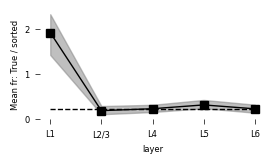

In [5]:
fig = plot_source_data(df)

In [6]:
fig.savefig(f"{OUT}/supp_fig7d.svg", bbox_inches="tight", **savefig_cfg)

## Save source data

In [7]:
df_save = df.reset_index() if df.index.name else df
df_save.to_excel(f"{OUT}/supp_fig7d.xlsx", sheet_name="mean_ratio", index=False)

## Replot from the saved source data (the xlsx is sufficient to reproduce the panel)

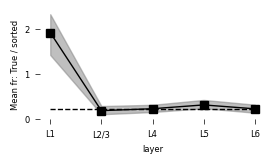

In [8]:
df = pd.read_excel(f"{OUT}/supp_fig7d.xlsx", index_col=0)
fig = plot_source_data(df)